# Fixed-column-count spatial averaging QC

This notebook analyzes target group sizes of 50, 100, 200, and 400 columns. Subject-level summaries are computed before cohort summaries.

In [ ]:

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

RESULT_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/results/native_surface_analysis"
)


def read_csv_files(paths):
    frames = [pd.read_csv(path) for path in paths if path.exists()]
    if not frames:
        return pd.DataFrame()
    return pd.concat(frames, ignore_index=True)


target_paths = sorted(
    (RESULT_ROOT / "spatial_averaging_target_sizes").glob(
        "D*/tables/target_group_size_metrics.csv"
    )
)
target_paths += sorted(
    (RESULT_ROOT / "spatial_averaging_target_sizes_existing").glob(
        "D*/tables/target_group_size_metrics.csv"
    )
)
target = read_csv_files(target_paths)
target = target.drop_duplicates(
    subset=["subject", "hemisphere", "region", "target_group_size", "k"]
)
target = target[target.status.eq("valid")].copy()

group_paths = sorted(
    (RESULT_ROOT / "spatial_averaging_target_sizes").glob(
        "D*/tables/target_group_size_groups.csv"
    )
)
group_paths += sorted(
    (RESULT_ROOT / "spatial_averaging_target_sizes_existing").glob(
        "D*/tables/target_group_size_groups.csv"
    )
)
groups = read_csv_files(group_paths)

fixed_paths = [
    RESULT_ROOT / "spatial_averaging_pilot/tables/metrics_summary.csv",
]
fixed_paths += sorted(
    (RESULT_ROOT / "spatial_averaging_five_subjects/shards").glob(
        "D*/tables/metrics_summary.csv"
    )
)
fixed = read_csv_files(fixed_paths)
fixed = fixed.drop_duplicates(
    subset=["subject", "hemisphere", "region", "method", "k", "repeat"]
)
fixed = fixed[
    fixed.status.eq("valid")
    & fixed.method.eq("region")
    & fixed.k.eq(1)
].copy()

print(f"Target-size subjects: {target.subject.nunique()}")
print(f"Target-size rows: {len(target):,}")
print(f"Subjects with whole-region baseline: {fixed.subject.nunique()}")
display(target.groupby("target_group_size")["subject"].nunique())


Target-size subjects: 39
Target-size rows: 1,093
Subjects with whole-region baseline: 9


target_group_size
50     39
100    39
200    39
400    39
Name: subject, dtype: int64

## Subject-level metrics and cohort summary

In [ ]:

target_subject = target.groupby(
    ["subject", "hemisphere", "region", "target_group_size"],
    as_index=False,
).agg(
    mae=("mae", "median"),
    rmse=("rmse", "median"),
    n_columns=("n_columns", "median"),
    k=("k", "median"),
)

baseline = fixed[
    ["subject", "hemisphere", "region", "mae"]
].rename(columns={"mae": "baseline_mae"})
target_subject = target_subject.merge(
    baseline,
    on=["subject", "hemisphere", "region"],
    how="left",
)
target_subject["mae_improvement_pct"] = 100 * (
    target_subject.baseline_mae - target_subject.mae
) / target_subject.baseline_mae

target_summary = target_subject.groupby(
    ["region", "target_group_size"],
    as_index=False,
).agg(
    n_subjects=("subject", "nunique"),
    n_subjects_with_baseline=(
        "mae_improvement_pct",
        lambda values: values.notna().sum(),
    ),
    mae_median=("mae", "median"),
    mae_q25=("mae", lambda values: values.quantile(0.25)),
    mae_q75=("mae", lambda values: values.quantile(0.75)),
    improvement_median=("mae_improvement_pct", "median"),
    improvement_q25=(
        "mae_improvement_pct",
        lambda values: values.quantile(0.25),
    ),
    improvement_q75=(
        "mae_improvement_pct",
        lambda values: values.quantile(0.75),
    ),
)
display(target_summary.round(4))


,region,target_group_size,n_subjects,n_subjects_with_baseline,mae_median,mae_q25,mae_q75,improvement_median,improvement_q25,improvement_q75
0,precentral,50,32,5,0.0001,0.0001,0.0001,36.4567,31.3789,37.0252
1,precentral,100,39,18,0.0001,0.0001,0.0001,28.1347,23.7802,30.5159
2,precentral,200,39,18,0.0001,0.0001,0.0001,18.1488,14.6148,20.6681
3,precentral,400,39,18,0.0001,0.0001,0.0001,12.2308,10.5647,14.1122
4,superiorfrontal,50,28,9,0.0001,0.0001,0.0001,28.1811,21.3794,28.5359
5,superiorfrontal,100,39,18,0.0001,0.0001,0.0001,17.0198,13.4987,19.9804
6,superiorfrontal,200,39,18,0.0001,0.0001,0.0001,10.3060,7.5490,12.3879
7,superiorfrontal,400,39,18,0.0001,0.0001,0.0001,4.8260,2.7984,8.6093
8,superiortemporal,50,22,5,0.0001,0.0001,0.0001,24.5800,21.8548,33.8235
9,superiortemporal,100,39,17,0.0001,0.0001,0.0001,15.9179,13.1896,18.3807


## Subject-level MAE curves

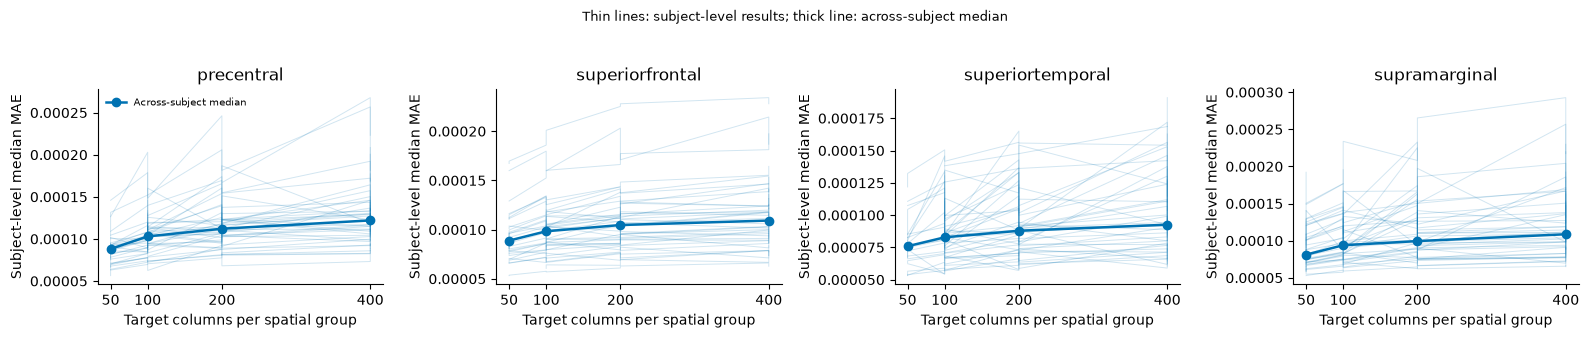

In [ ]:

regions = sorted(target_summary.region.unique())
fig, axes = plt.subplots(
    1,
    len(regions),
    figsize=(4 * len(regions), 3.4),
    squeeze=False,
)
for ax, region in zip(axes.ravel(), regions):
    part = target_subject[target_subject.region.eq(region)]
    for subject, group in part.groupby("subject"):
        group = group.sort_values("target_group_size")
        ax.plot(
            group.target_group_size,
            group.mae,
            color="#0072B2",
            alpha=0.18,
            linewidth=0.7,
        )
    median = target_summary[target_summary.region.eq(region)]
    ax.plot(
        median.target_group_size,
        median.mae_median,
        color="#0072B2",
        marker="o",
        linewidth=1.8,
        label="Across-subject median",
    )
    ax.set_title(region)
    ax.set_xlabel("Target columns per spatial group")
    ax.set_ylabel("Subject-level median MAE")
    ax.set_xticks(sorted(target.target_group_size.unique()))
    ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.suptitle(
    "Thin lines: subject-level results; thick line: across-subject median",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## Subject-level improvement curves

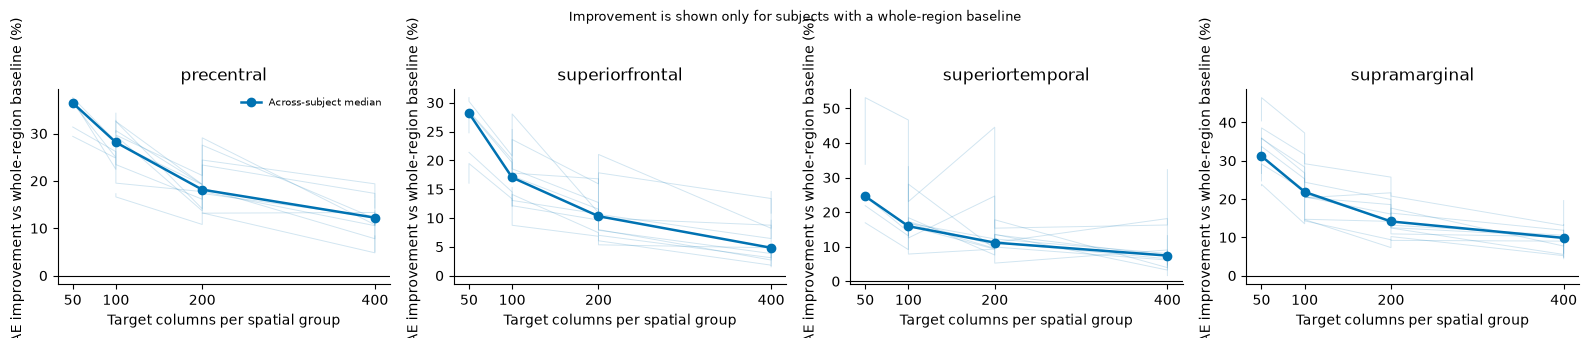

In [ ]:

regions = sorted(target_summary.region.unique())
fig, axes = plt.subplots(
    1,
    len(regions),
    figsize=(4 * len(regions), 3.4),
    squeeze=False,
)
for ax, region in zip(axes.ravel(), regions):
    part = target_subject[target_subject.region.eq(region)]
    for subject, group in part.groupby("subject"):
        group = group.dropna(subset=["mae_improvement_pct"])
        group = group.sort_values("target_group_size")
        ax.plot(
            group.target_group_size,
            group.mae_improvement_pct,
            color="#0072B2",
            alpha=0.18,
            linewidth=0.7,
        )
    median = target_summary[target_summary.region.eq(region)]
    ax.plot(
        median.target_group_size,
        median.improvement_median,
        color="#0072B2",
        marker="o",
        linewidth=1.8,
        label="Across-subject median",
    )
    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_title(region)
    ax.set_xlabel("Target columns per spatial group")
    ax.set_ylabel("MAE improvement vs whole-region baseline (%)")
    ax.set_xticks(sorted(target.target_group_size.unique()))
    ax.spines[["top", "right"]].set_visible(False)
axes.ravel()[0].legend(frameon=False, fontsize=7)
fig.suptitle(
    "Improvement is shown only for subjects with a whole-region baseline",
    fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()


## Actual columns per target group

,region,target_group_size,n_subjects,median_columns_per_group,q25_columns_per_group,q75_columns_per_group
0,precentral,50,39,48.0,36.00,61.0
1,precentral,100,39,98.0,67.00,124.0
2,precentral,200,39,184.0,127.00,260.0
3,precentral,400,39,344.0,251.75,502.0
4,superiorfrontal,50,39,50.0,40.00,60.0
5,superiorfrontal,100,39,101.0,78.00,121.0
6,superiorfrontal,200,39,204.0,139.00,250.0
7,superiorfrontal,400,39,383.0,264.50,517.0
8,superiortemporal,50,39,50.0,37.00,62.0
9,superiortemporal,100,39,101.0,70.00,126.0


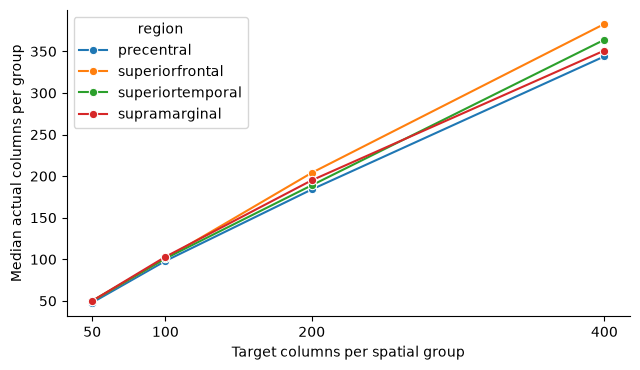

In [ ]:

group_summary = groups.groupby(
    ["region", "target_group_size"],
    as_index=False,
).agg(
    n_subjects=("subject", "nunique"),
    median_columns_per_group=("n_columns", "median"),
    q25_columns_per_group=("n_columns", lambda values: values.quantile(0.25)),
    q75_columns_per_group=("n_columns", lambda values: values.quantile(0.75)),
)
display(group_summary.round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.8))
sns.lineplot(
    data=group_summary,
    x="target_group_size",
    y="median_columns_per_group",
    hue="region",
    marker="o",
    ax=ax,
)
ax.set_xlabel("Target columns per spatial group")
ax.set_ylabel("Median actual columns per group")
ax.set_xticks(sorted(target.target_group_size.unique()))
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()
